In [72]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)

In [73]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("final_merged_dataset_2000_2022_with_education_over65.xlsx")

preview = df.head(5)

print("\nFirst 5 rows:")
display(preview)



First 5 rows:


,Country,Year,Life_Expectancy,GDP_PPP,Physicians_per_1000,Alcohol_Consumption,Health_Exp_PPP,Over65_Pct,Edu_Tertiary
0,Austria,2000,78.3,51975.7,3.85,13.2,4718.938,15.426,17.500000
1,Austria,2001,78.8,52416.1,3.96,12.3,4776.365,15.463,17.800000
2,Austria,2002,78.9,52931.3,4.03,12.1,4895.074,15.456,18.100000
3,Austria,2003,78.8,53293.5,4.11,12.3,4967.350,15.444,18.500000
4,Austria,2004,79.3,54241.5,4.20,12.1,5123.730,15.707,24.783438


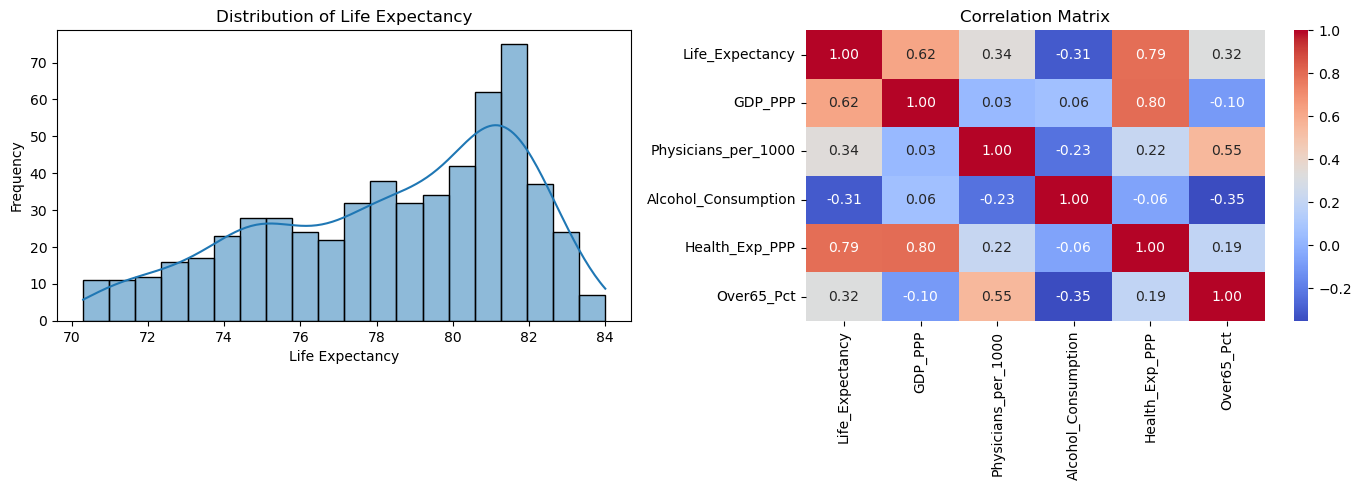

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.nonparametric.smoothers_lowess import lowess

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Histogram
sns.histplot(df["Life_Expectancy"], bins=20, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Life Expectancy")
axes[0].set_xlabel("Life Expectancy")
axes[0].set_ylabel("Frequency")

# Correlation Heatmap
corr = df[[
    "Life_Expectancy",
    "GDP_PPP",
    "Physicians_per_1000",
    "Alcohol_Consumption",
    "Health_Exp_PPP",
    "Over65_Pct"
]].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1])
axes[1].set_title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [98]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


df = pd.read_excel("final_merged_dataset_2000_2022_with_education_over65.xlsx") # Load the data

df = df.drop_duplicates()
df = df.dropna(subset=["Life_Expectancy"])


# Target and features
target = "Life_Expectancy"

features = [
    "GDP_PPP",
    "Physicians_per_1000",
    "Alcohol_Consumption",
    "Health_Exp_PPP",
    "Over65_Pct"
]

df["Year"] = pd.to_numeric(df["Year"], errors="coerce")

# Train and split based on years 
train_df = df[df["Year"] <= 2018].copy()
test_df  = df[df["Year"] > 2018].copy()

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Train years:", int(train_df["Year"].min()), "-", int(train_df["Year"].max()))
print("Test years :", int(test_df["Year"].min()), "-", int(test_df["Year"].max()))
print("Train size :", len(train_df))
print("Test size  :", len(test_df))

# Linear regression 
lr_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("lr", LinearRegression())
])

lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

print("\n---- Linear Regression ----")
print("MAE :", round(mean_absolute_error(y_test, lr_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, lr_pred)), 3))
print("R^2 :", round(r2_score(y_test, lr_pred), 3))

# Random forest 
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("\n---- Random Forest ----")
print("MAE :", round(mean_absolute_error(y_test, rf_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, rf_pred)), 3))
print("R^2 :", round(r2_score(y_test, rf_pred), 3))

# Final table with comparison of
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, rf_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],
    "R2": [
        r2_score(y_test, lr_pred),
        r2_score(y_test, rf_pred)
    ]
})

print("\n---- Model Comparison ----")
display(results)


Train years: 2000 - 2018
Test years : 2019 - 2022
Train size : 475
Test size  : 100

---- Linear Regression ----
MAE : 1.787
RMSE: 2.25
R^2 : 0.495

---- Random Forest ----
MAE : 1.661
RMSE: 2.446
R^2 : 0.403

---- Model Comparison ----


,Model,MAE,RMSE,R2
0,Linear Regression,1.786716,2.249746,0.494942
1,Random Forest,1.661378,2.445727,0.403115


In [99]:
# Random Forest modeling (baseline)

rf_base = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    ))
])

rf_base.fit(X_train, y_train)
rf_base_pred = rf_base.predict(X_test)

print("\n---- Random Forest (Baseline) ----")
print("MAE :", round(mean_absolute_error(y_test, rf_base_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, rf_base_pred)), 3))
print("R^2 :", round(r2_score(y_test, rf_base_pred), 3))



# Random Forest modeling (tuned): for better result and reduce overfitting 

rf_tuned = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2,   # stabilizer
        max_features="sqrt"   # improves generalization
    ))
])

rf_tuned.fit(X_train, y_train)
rf_tuned_pred = rf_tuned.predict(X_test)

print("\n---- Random Forest (Tuned: min_leaf=2, max_features=sqrt) ----")
print("MAE :", round(mean_absolute_error(y_test, rf_tuned_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, rf_tuned_pred)), 3))
print("R^2 :", round(r2_score(y_test, rf_tuned_pred), 3))


# Comparison Table to show the accuracy for both random forest models and to use in the report 

rf_compare = pd.DataFrame({
    "Model": ["RF Baseline", "RF Tuned"],
    "MAE": [
        mean_absolute_error(y_test, rf_base_pred),
        mean_absolute_error(y_test, rf_tuned_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, rf_base_pred)),
        np.sqrt(mean_squared_error(y_test, rf_tuned_pred))
    ],
    "R2": [
        r2_score(y_test, rf_base_pred),
        r2_score(y_test, rf_tuned_pred)
    ]
})

print("\n---- RF Baseline vs Tuned ----")
display(rf_compare)



---- Random Forest (Baseline) ----
MAE : 1.661
RMSE: 2.446
R^2 : 0.403

---- Random Forest (Tuned: min_leaf=2, max_features=sqrt) ----
MAE : 1.525
RMSE: 2.182
R^2 : 0.525

---- RF Baseline vs Tuned ----


,Model,MAE,RMSE,R2
0,RF Baseline,1.661378,2.445727,0.403115
1,RF Tuned,1.525386,2.181574,0.525087


In [80]:
# Linear Regression Predictions
test_df["LR_Prediction"] = lr_model.predict(X_test)

# Random Forest Tuned Model Predictions
test_df["RF_Prediction"] = rf_tuned.predict(X_test)

# Comparison table 
prediction_table = test_df[[
    "Country",
    "Year",
    "Life_Expectancy",
    "LR_Prediction",
    "RF_Prediction"
]]

display(prediction_table.head())


,Country,Year,Life_Expectancy,LR_Prediction,RF_Prediction
19,Austria,2019,82.0,83.209685,81.521512
20,Austria,2020,81.3,83.396744,81.340828
21,Austria,2021,81.3,84.574466,81.398161
22,Austria,2022,81.4,83.876081,81.401252
42,Belgium,2019,82.1,82.975334,81.637114


In [81]:
# To visualize the predictions for both linear regression and random forest 

test_df["LR_Prediction"] = lr_model.predict(X_test)
test_df["RF_Prediction"] = rf_tuned.predict(X_test)

# Table for each country 
country_table = test_df[[
    "Country",
    "Year",
    "Life_Expectancy",
    "LR_Prediction",
    "RF_Prediction"
]]

display(country_table)


,Country,Year,Life_Expectancy,LR_Prediction,RF_Prediction
19,Austria,2019,82.0,83.209685,81.521512
20,Austria,2020,81.3,83.396744,81.340828
21,Austria,2021,81.3,84.574466,81.398161
22,Austria,2022,81.4,83.876081,81.401252
42,Belgium,2019,82.1,82.975334,81.637114
...,...,...,...,...,...
551,Spain,2022,83.2,79.487794,80.722703
571,Sweden,2019,83.2,84.317867,82.272113
572,Sweden,2020,82.4,84.261047,82.152562
573,Sweden,2021,83.1,84.667379,82.034429


In [82]:
country_summary = test_df.groupby("Country").apply(
    lambda x: pd.Series({
        "Actual_Mean": x["Life_Expectancy"].mean(),
        "LR_Mean": x["LR_Prediction"].mean(),
        "RF_Mean": x["RF_Prediction"].mean(),
        "LR_MAE": np.mean(np.abs(x["Life_Expectancy"] - x["LR_Prediction"])),
        "RF_MAE": np.mean(np.abs(x["Life_Expectancy"] - x["RF_Prediction"]))
    })
).reset_index()

display(country_summary.sort_values("RF_MAE"))


,Country,Actual_Mean,LR_Mean,RF_Mean,LR_MAE,RF_MAE
0,Austria,81.500,83.764244,81.415438,2.264244,0.154682
5,Denmark,81.475,83.649869,81.312872,2.174869,0.162128
7,Finland,81.800,82.383039,81.860633,0.672313,0.284249
17,Netherlands,81.675,84.513046,81.754102,2.838046,0.365782
1,Belgium,81.650,83.488948,81.667924,1.838948,0.419797
19,Portugal,81.675,80.514056,81.327864,1.160944,0.445401
22,Slovenia,81.050,79.506185,81.309981,1.543815,0.463186
9,Germany,80.975,85.350215,81.459162,4.375215,0.484162
13,Italy,82.850,81.919313,82.443148,0.930687,0.682978
10,Greece,81.025,80.901349,81.193043,0.735397,0.771384


In [83]:
country_summary.sort_values("RF_MAE", ascending=False).head(5)

,Country,Actual_Mean,LR_Mean,RF_Mean,LR_MAE,RF_MAE
15,Lithuania,75.425,78.470520,80.086922,3.045520,4.661922
2,Bulgaria,73.450,77.689641,77.630144,4.239641,4.180144
11,Hungary,75.525,77.537245,79.004045,2.012245,3.479045
14,Latvia,74.700,77.029563,77.886330,2.329563,3.186330
20,Romania,74.425,76.665255,76.824493,2.240255,2.399493


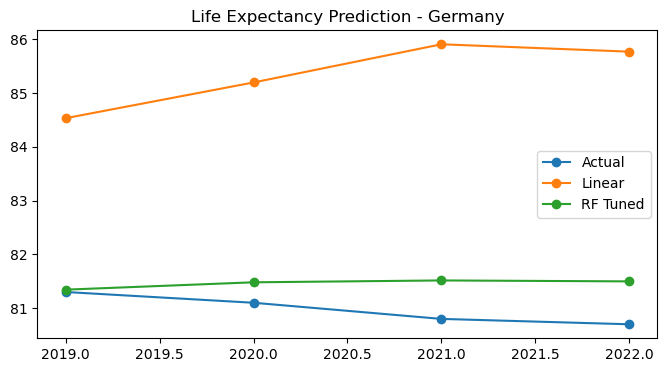

In [84]:
# This part is just to visualize how predictions vary across models (for a specific country)

country = "Germany"

subset = test_df[test_df["Country"] == country]

plt.figure(figsize=(8,4))
plt.plot(subset["Year"], subset["Life_Expectancy"], label="Actual", marker="o")
plt.plot(subset["Year"], subset["LR_Prediction"], label="Linear", marker="o")
plt.plot(subset["Year"], subset["RF_Prediction"], label="RF Tuned", marker="o")

plt.title(f"Life Expectancy Prediction - {country}")
plt.legend()
plt.show()


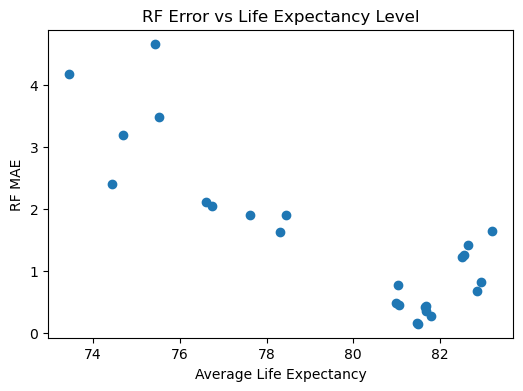

In [86]:
# Extra visualization  

import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.scatter(analysis_df["Actual_Mean"], analysis_df["RF_MAE"])

plt.xlabel("Average Life Expectancy")
plt.ylabel("RF MAE")
plt.title("RF Error vs Life Expectancy Level")

plt.show()

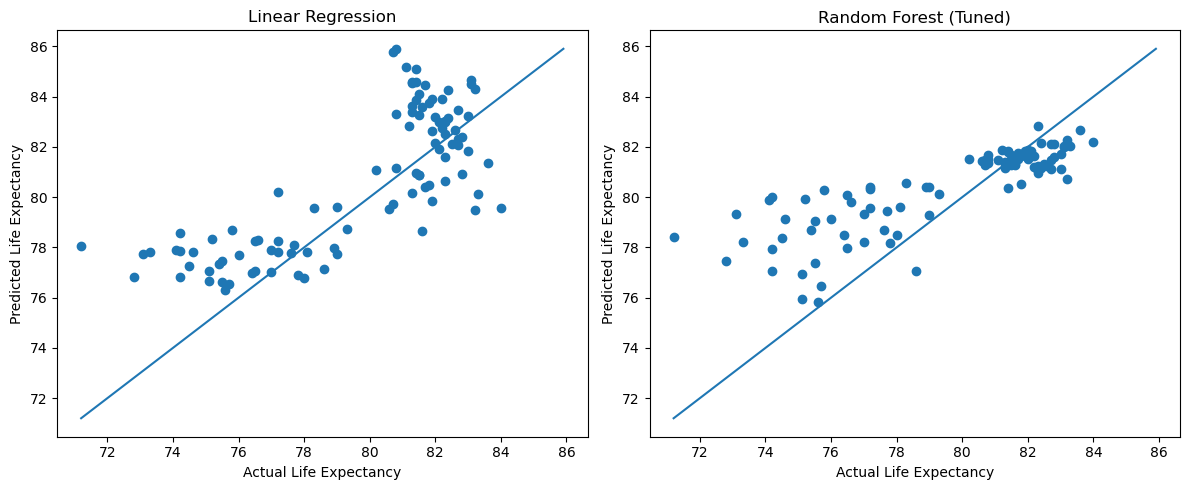

In [87]:
# This cell is just to visualize

import matplotlib.pyplot as plt
import numpy as np

# Predictions
lr_pred = lr_model.predict(X_test)
rf_pred = rf_tuned.predict(X_test)

# Min-max values
min_val = min(y_test.min(), lr_pred.min(), rf_pred.min())
max_val = max(y_test.max(), lr_pred.max(), rf_pred.max())

# Create side-by-side plots
plt.figure(figsize=(12,5))

# Linear Regression Plot
plt.subplot(1, 2, 1)
plt.scatter(y_test, lr_pred)
plt.plot([min_val, max_val], [min_val, max_val])
plt.xlabel("Actual Life Expectancy")
plt.ylabel("Predicted Life Expectancy")
plt.title("Linear Regression")

# Random Forest Plot
plt.subplot(1, 2, 2)
plt.scatter(y_test, rf_pred)
plt.plot([min_val, max_val], [min_val, max_val])
plt.xlabel("Actual Life Expectancy")
plt.ylabel("Predicted Life Expectancy")
plt.title("Random Forest (Tuned)")

plt.tight_layout()
plt.show()


In [100]:
# MLP Modeling 

import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")


import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the dataset
df = pd.read_excel("final_merged_dataset_2000_2022_with_education_over65.xlsx")
df = df.drop_duplicates()
df = df.dropna(subset=["Life_Expectancy"])
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")

# Log transformation
for col in ["GDP_PPP", "Health_Exp_PPP"]:
    df[col] = np.log1p(df[col])

target = "Life_Expectancy"
features = ["GDP_PPP","Physicians_per_1000","Alcohol_Consumption","Health_Exp_PPP","Over65_Pct"]

# Time split 
train_df = df[df["Year"] <= 2018].copy()
test_df  = df[df["Year"] > 2018].copy()

X_train = train_df[features]
y_train = train_df[target]
X_test  = test_df[features]
y_test  = test_df[target]

# Pipeline 
pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(
        random_state=42,
        max_iter=8000,
        early_stopping=True,
        validation_fraction=0.2,
        n_iter_no_change=50
    ))
])

# Grid 
param_grid = {
    "mlp__hidden_layer_sizes": [(16,8), (32,16), (32,16,8)],
    "mlp__activation": ["relu", "tanh"],
    "mlp__alpha": [0.001, 0.01, 0.05, 0.1],
    "mlp__learning_rate_init": [0.001, 0.0005],
    "mlp__solver": ["adam"]
}

tscv = TimeSeriesSplit(n_splits=5)

grid = GridSearchCV(
    pipe,
    param_grid=param_grid,
    cv=tscv,
    scoring="r2",
    n_jobs=1
)

grid.fit(X_train, y_train)

print("Best CV R2:", round(grid.best_score_, 3))
print("Best Params:", grid.best_params_)

best_mlp = grid.best_estimator_

# Evaluation
test_pred = best_mlp.predict(X_test)

print("\n---- BEST MLP (Tuned) TEST RESULTS ----")
print("Test R2 :", round(r2_score(y_test, test_pred), 3))
print("MAE     :", round(mean_absolute_error(y_test, test_pred), 3))
print("RMSE    :", round(np.sqrt(mean_squared_error(y_test, test_pred)), 3))


Best CV R2: 0.15
Best Params: {'mlp__activation': 'tanh', 'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes': (32, 16), 'mlp__learning_rate_init': 0.001, 'mlp__solver': 'adam'}

---- BEST MLP (Tuned) TEST RESULTS ----
Test R2 : 0.451
MAE     : 1.635
RMSE    : 2.345
